# 03 · Word vectors: do they understand titles better than TF-IDF?

**Goal:** check whether pretrained word vectors (GloVe) fix TF-IDF's main weakness, which is that it only matches identical words, and what they cost.

**Recap of Step 2:** TF-IDF + cosine gave every candidate a similarity score, and from it an automatic label (16 fit, 18 not a fit, 19 unsure). TF-IDF can't see that different words can mean similar things ("people development" and "human resources"). Word vectors are built to capture exactly that.

**How we judge, without hand labels:**
1. **Sanity check:** does GloVe agree with the clear-cut automatic labels?
2. **Agreement:** how similarly do GloVe and TF-IDF order the candidates?
3. **Hard cases:** the tricky titles we listed in Step 1, *before* any method existed.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

from talent_ranker.config import FIGURES_DIR, KEYWORDS, WORD_VECTORS
from talent_ranker.data import deduplicate, load_candidates
from talent_ranker.embeddings import (
    embedding_similarity,
    load_word_vectors,
    title_words,
)
from talent_ranker.labelling import auto_label
from talent_ranker.similarity import idf_weights, tfidf_similarity

pd.set_option("display.max_colwidth", 80)
profiles = deduplicate(load_candidates())
profiles["tfidf"] = tfidf_similarity(profiles["job_title"], KEYWORDS)
profiles["auto_label"] = auto_label(profiles["tfidf"])
print(
    f"{len(profiles)} profiles, {profiles['auto_label'].notna().sum()} with an automatic label"
)

53 profiles, 34 with an automatic label


## 1. Pretrained word vectors
A **word vector** is a list of numbers that places each word in a "meaning space". Words used in similar contexts end up close together.

**Why pretrained:** vectors learn meaning from millions of sentences. Our titles hold only 329 words, far too few to learn anything, so we borrow vectors trained on a huge general corpus.

| Option | Verdict | Reason |
|---|---|---|
| Train our own word2vec | ❌ | 329 words is far too little text to learn meaning |
| **GloVe 100d** | ✅ chosen | Trained on 6 billion words of Wikipedia + news (formal text, like job titles); 128 MB; lowercase; 100 numbers per word is enough for short titles |
| GloVe 300d | ⏭ | 3× larger for usually small gains; a one-line config change if needed |
| word2vec Google News | ❌ | 1.6 GB and case-sensitive, with no clear advantage here |
| fastText | ❌ | Its strength (vectors for unknown words) needs a several-GB model; our unknown words are company names, where word pieces wouldn't help |
| SBERT | ⏭ | Reads whole sentences but is much heavier. Simpler first |

In [2]:
vectors = (
    load_word_vectors()
)  # the first run downloads about 128 MB; later runs use the cache
print(
    f"{WORD_VECTORS}: {len(vectors.key_to_index):,} words, {vectors.vector_size} numbers each"
)

[==================================================] 100.0% 128.1/128.1MB downloaded
glove-wiki-gigaword-100: 400,000 words, 100 numbers each


## 2. What do the vectors know?
The nearest neighbours of a word show what the vectors learned about it.

In [3]:
for word in ["hr", "aspiring", "seeking"]:
    neighbours = [w for w, _ in vectors.most_similar(word, topn=8)]
    print(f"{word:>9}: {', '.join(neighbours)}")

       hr: =, rbi, avg, ip, mins, sb, triples, .293
 aspiring: up-and-coming, young, filmmakers, talented, mentors, actresses, wannabe, budding
  seeking: seek, sought, seeks, trying, hoping, help, attempting, claiming


**Finding:**
- **"hr" means "home runs" in GloVe.** Its neighbours are baseball statistics (rbi, avg, ip, triples), because the vectors learned from news text full of sports scores. Without spelling "HR" out as "human resources", every HR title would be read as baseball.
- **"aspiring"** sits near *up-and-coming, young, talented, budding, wannabe*. The vectors do capture "early career".
- **"seeking"** sits near *seek, sought, trying, hoping, attempting*.

In [4]:
pairs = [("people", "human"), ("personnel", "resources"), ("teacher", "resources")]
pd.Series({f"{a} ~ {b}": vectors.similarity(a, b) for a, b in pairs}).round(2)

people ~ human           0.60
personnel ~ resources    0.50
teacher ~ resources      0.24
dtype: float32

**Finding:** related words are close even though they share no letters: people ~ human **0.60**, personnel ~ resources **0.50**, against teacher ~ resources **0.24**. TF-IDF scores all three pairs 0, because the words are different.

## 3. Do the vectors know our words?
A word GloVe doesn't know simply can't be used, so we check how many of our title words it covers.

In [5]:
all_words = [w for title in profiles["job_title"] for w in title_words(title)]
unknown = sorted({w for w in all_words if w not in vectors.key_to_index})
known_share = sum(w in vectors.key_to_index for w in all_words) / len(all_words)
print(f"{len(all_words)} words in the titles, {known_share:.1%} known to GloVe")
print("Unknown:", unknown)

329 words in the titles, 97.6% known to GloVe
Unknown: ['engie', 'gphr', 'hris', 'loparex', 'nortia', 'scottmadden', 'sphr', 'styczynski']


**Finding: GloVe knows 97.6% of our title words.** The 8 unknown words are:
- company names: Engie, Loparex, Nortia, ScottMadden;
- a lab name: Styczynski;
- HR certification codes: GPHR, SPHR, HRIS.

None of them carries the "aspiring" or "seeking" signal, so losing them costs little. Every title keeps at least one known word.

## 4. From words to one vector per title
**Title vector = the average of its word vectors.** Stop words are removed, "HR" is spelled out, and unknown words are skipped. Each title is then compared with each keyword using **cosine similarity**, and the better keyword match is kept, exactly as with TF-IDF so the comparison is fair.

In [6]:
profiles["glove"] = embedding_similarity(profiles["job_title"], KEYWORDS, vectors)
ranked = profiles.sort_values("glove", ascending=False)
ranked[["job_title", "tfidf", "glove"]].head(15).round(3)

,job_title,tfidf,glove
13,Seeking Human Resources Opportunities,0.674,0.968
47,Seeking Human Resources Position,0.674,0.963
5,Aspiring Human Resources Specialist,0.676,0.953
45,Aspiring Human Resources Professional,0.756,0.949
2,Aspiring Human Resources Professional,0.756,0.949
21,"Aspiring Human Resources Manager, seeking internship in Human Resources.",0.628,0.939
8,Seeking Human Resources HRIS and Generalist Positions,0.432,0.923
22,Human Resources Professional,0.394,0.922
36,Human Resources Management Major,0.253,0.902
42,Seeking Human Resources Opportunities. Open to travel and relocation.,0.370,0.900


**Finding:** the top is still the short "Aspiring / Seeking Human Resources …" titles (0.94–0.97). New entrants appear in the top 15:
- the HR student ("Human Resources Management Major", 0.902), who was "unsure" for TF-IDF;
- working HR professionals: "Human Resources Generalist at Loparex" (0.879) and "HR Senior Specialist" (0.861).

GloVe recognises *HR* better, but it no longer separates *aspiring* from *already working*.

## 5. Are the choices right? (each one tested)
We compare the chosen setup with three alternatives, first on example titles, then on two numbers computed on the 34 profiles that have a confident automatic label:
- **AUC:** the chance that a random "fit" profile scores higher than a random "not a fit" one (1.0 = perfect separation). We use AUC here because we're checking how well two groups are *separated*, not the order at the top of a list.
- **Gap between group medians:** how far apart the two groups sit. Bigger is clearer.

In [7]:
titles = profiles["job_title"]
variants = pd.DataFrame(
    {
        "HR not spelled out": embedding_similarity(
            titles, KEYWORDS, vectors, expand_abbreviations=False
        ),
        "stop words kept": embedding_similarity(
            titles, KEYWORDS, vectors, remove_stop_words=False
        ),
        "IDF-weighted average": embedding_similarity(
            titles, KEYWORDS, vectors, weights=idf_weights(titles)
        ),
        "chosen": profiles["glove"],
    }
)
examples = [
    "HR Senior Specialist",
    "HR Manager at Endemol Shine North America",
    "Bachelor of Science in Biology from Victoria University of Wellington",
    "2019 C.T. Bauer College of Business Graduate (Magna Cum Laude) and aspiring Human "
    "Resources professional",
]
shown = variants.set_index(titles)
shown[~shown.index.duplicated()].loc[examples].round(3)

,HR not spelled out,stop words kept,IDF-weighted average,chosen
job_title,,,,
HR Senior Specialist,0.488,0.861,0.710,0.861
HR Manager at Endemol Shine North America,0.544,0.783,0.653,0.798
Bachelor of Science in Biology from Victoria University of Wellington,0.485,0.620,0.477,0.485
2019 C.T. Bauer College of Business Graduate (Magna Cum Laude) and aspiring Human Resources professional,0.606,0.662,0.479,0.606


In [8]:
confident = profiles["auto_label"].notna()
fit = profiles.loc[confident, "auto_label"].astype(int)
checks = {}
for name in variants:
    scores = variants.loc[confident, name]
    checks[name] = {
        "AUC on confident labels": roc_auc_score(fit, scores),
        "gap between group medians": scores[fit == 1].median()
        - scores[fit == 0].median(),
    }
pd.DataFrame(checks).T.round(3)

,AUC on confident labels,gap between group medians
HR not spelled out,1.000,0.328
stop words kept,1.000,0.294
IDF-weighted average,0.972,0.234
chosen,1.000,0.328


**Finding: every choice is justified by a number.**

| Variant | Evidence | Verdict |
|---|---|---|
| HR not spelled out | "HR Senior Specialist" **0.488** (read as baseball) vs **0.861** when spelled out; "HR Manager" 0.544 vs 0.798. The AUC and gap are unchanged only because no "HR" title has a confident label | Spell it out ✅ |
| Stop words kept | Generic words pull everything together: "Biology" rises from 0.485 to **0.620**, and the gap shrinks from 0.328 to **0.294** | Remove them ✅ |
| IDF-weighted average | Rare words dominate, and in titles the rarest words are names ("Bauer", "Magna", "Laude"). The C.T. Bauer graduate falls to 0.479; the AUC drops to **0.972** and the gap to **0.234** | Rejected ❌ |
| **Chosen** (plain average, stop words removed, HR spelled out) | AUC **1.0**, gap **0.328**, the best of all variants | ✅ |

The AUC of 1.0 means GloVe agrees with every clear-cut automatic label. Since those labels came from TF-IDF, this is a sanity check, not proof that GloVe is better.

## 6. TF-IDF vs GloVe
**Spearman rank correlation** measures whether two methods put candidates in the same order: 1 means identical order, 0 means unrelated.

In [9]:
rho = spearmanr(profiles["tfidf"], profiles["glove"]).statistic
print(f"Rank agreement, TF-IDF vs GloVe (Spearman): {rho:.2f}")
profiles[["tfidf", "glove"]].describe().loc[["min", "50%", "max"]].round(2)

Rank agreement, TF-IDF vs GloVe (Spearman): 0.85


,tfidf,glove
min,0.00,0.44
50%,0.22,0.82
max,0.76,0.97


**Finding:**
- **The two methods mostly agree (Spearman 0.85)**, so GloVe changes the details, not the big picture.
- **The score ranges are very different.** TF-IDF goes from **0** to 0.76, with a median of 0.22. GloVe never drops below **0.44**, and its median is **0.82**, because every job title is "somewhat similar" in meaning to every other.
- So **a threshold can't be reused across methods**: 0.3 means "clear fit" for TF-IDF but would include everyone with GloVe. This matters again for the cut-off question (Step 6).

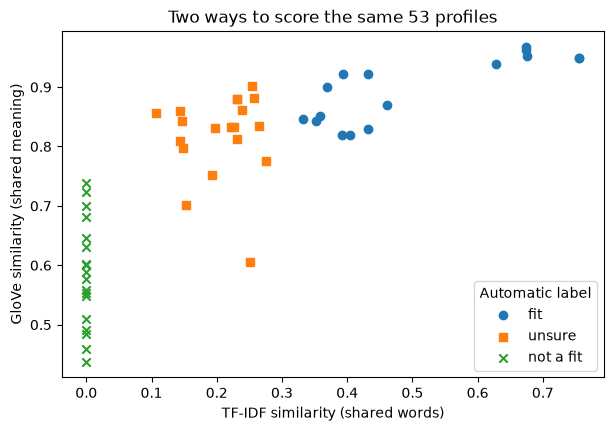

In [10]:
zone = profiles["auto_label"].map({1: "fit", 0: "not a fit"}).fillna("unsure")
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, marker in [("fit", "o"), ("unsure", "s"), ("not a fit", "x")]:
    group = profiles[zone == name]
    ax.scatter(group["tfidf"], group["glove"], marker=marker, label=name)
ax.set(
    title="Two ways to score the same 53 profiles",
    xlabel="TF-IDF similarity (shared words)",
    ylabel="GloVe similarity (shared meaning)",
)
ax.legend(title="Automatic label")
fig.savefig(FIGURES_DIR / "tfidf_vs_glove.png", dpi=150, bbox_inches="tight")

**Finding:**
- **"Not a fit" (×)** sits on a vertical line at TF-IDF = 0, because these titles share no keyword word. GloVe still spreads them from 0.44 to 0.74: some are closer in meaning to HR than others.
- **"Unsure" (■)** has low TF-IDF scores but **high GloVe scores (mostly 0.75–0.9)**, overlapping the "fit" group. To GloVe these titles look like HR, which most of them are.
- The one unsure point far below the rest (TF-IDF 0.25, GloVe 0.61) is the long C.T. Bauer title, diluted by its many other words.

## 7. The hard cases from Step 1
Rank 1 is best. Ties share the same rank: all titles with TF-IDF = 0 are rank 36.

In [11]:
hard_cases = {
    "2019 C.T. Bauer": "aspiring, long title",
    "Retired Army": "seeking, long title",
    "Human Resources Management Major": "HR student",
    "Student at Humber College": "aspiring student",
    "Experienced Retail Manager": "aspiring career changer",
    "Generalist at Loparex": "working in HR",
    "HR Senior Specialist": "working in HR",
    "Director Human Resources at EY": "working in HR, senior",
    "People Development": "HR in other words",
    "Nortia": "job ad",
    "Native English Teacher": "not HR",
}
ranks = profiles[["tfidf", "glove"]].rank(ascending=False, method="min").astype(int)
rows = []
for text, kind in hard_cases.items():
    i = profiles.index[profiles["job_title"].str.contains(text, regex=False)][0]
    rows.append(
        {
            "title": profiles.at[i, "job_title"][:50],
            "what it is": kind,
            "TF-IDF rank": ranks.at[i, "tfidf"],
            "GloVe rank": ranks.at[i, "glove"],
        }
    )
pd.DataFrame(rows)

,title,what it is,TF-IDF rank,GloVe rank
0,2019 C.T. Bauer College of Business Graduate (Magn,"aspiring, long title",21,41
1,"Retired Army National Guard Recruiter, office mana","seeking, long title",17,32
2,Human Resources Management Major,HR student,20,9
3,Student at Humber College and Aspiring Human Resou,aspiring student,12,27
4,Experienced Retail Manager and aspiring Human Reso,aspiring career changer,10,28
5,Human Resources Generalist at Loparex,working in HR,23,12
6,HR Senior Specialist,working in HR,22,15
7,Director Human Resources at EY,"working in HR, senior",27,23
8,People Development Coordinator at Ryan,HR in other words,36,35
9,"Nortia Staffing is seeking Human Resources, Payrol",job ad,18,22


**Finding: each method is good at a different question.**

| Question | TF-IDF | GloVe | Evidence (TF-IDF rank → GloVe rank) |
|---|---|---|---|
| **Is this person in HR at all?** | weaker | ✅ **better** | HR student 20 → **9**; HR Generalist 23 → **12**; HR Senior Specialist 22 → **15**; English teacher 36 → 45 |
| **Are they *aspiring*, or already working?** | ✅ **better** | weaker | aspiring career changer 10 → 28; Humber student 12 → 27; Retired Army (seeking) 17 → 32 |
| **Long titles** | weak | ❌ **worse** | C.T. Bauer graduate 21 → **41**: averaging 10+ words drowns the one word "aspiring" |
| **HR in other words** | ❌ | ❌ | "People Development Coordinator" 36 → 35: "people" is close to "human" (0.60), but "development" and "coordinator" pull the average away |
| **Job ad** | ❌ | ❌ | Nortia ranks 18 → 22 with both. It's a content problem, not a wording one; Step 6 filters it |

**Why:** averaging treats every word equally, so the one word that marks the career stage ("aspiring", "seeking") is outweighed by the domain words around it. TF-IDF scores those exact words directly.

## Summary

| Question | Answer |
|---|---|
| Do word vectors understand meaning? | **Yes:** people ~ human 0.60, personnel ~ resources 0.50. But "hr" means *home runs* unless spelled out |
| Coverage | **97.6%** of title words are known; the unknown ones are company names and certification codes |
| Best setup | Plain average, stop words removed, HR spelled out. IDF weighting was tested and **rejected** (AUC 0.972, gap 0.234 vs 0.328) |
| GloVe vs TF-IDF | They mostly agree (Spearman 0.85). **GloVe is better at "is this HR?"; TF-IDF is better at "aspiring vs already working"** |
| Scores comparable across methods? | **No:** GloVe 0.44–0.97 vs TF-IDF 0–0.76, so thresholds can't be shared |

**Decision:** neither method wins outright, so we keep both, each for what it does best.
- **TF-IDF stays the labeller.** Its zeros are certain "not a fit" cases, and it scores the exact career-stage words.
- **GloVe adds the meaning view.**

**Next:** train a model on the automatic labels, so that fit becomes a probability, and test which input works best: TF-IDF, GloVe, or both. One thing to watch: every confident "not a fit" example is a non-HR title, so a model may learn "HR vs not HR" rather than "aspiring vs working". Step 4 measures this, and Step 5's expert stars are what teach that preference.